In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as spi
from scipy.signal import argrelextrema

#The constants
grav_const = 6.67430e-11 
sun_mass = 1.989e30   #kg
mercury_mass = 3.302e23   #kg   ref: NASA Horizons 2024-Mar-04
speed_of_light = 2.99792458e8   #m/s
ecc = 0.205628   #ref: NASA Horizons 2024-Mar-04
semi_major = 5.7909e10   #m   ref: NASA Horizons 2024-Mar-04
mercury_period = 87.969257   #days  ref: NASA Horizons 2024-Mar-04
earth_period = 365.25636   #days   ref: NASA Horizons 2024-Mar-04
number_of_cycle = earth_period * 100 / mercury_period

#h**2 value
l = semi_major * (1 - ecc**2)
h_sq = grav_const * sun_mass * l

#Take several hundred centuries so that the shift is more obvious, the phi_plots are for plotting
#the full dataset for 600 centuries
phi = np.linspace(0*number_of_cycle*2*np.pi, 600*number_of_cycle*2*np.pi, 100000000)
phi_plot = phi[-200:]
#first 200 centuries
phi1 = np.linspace(0*number_of_cycle*2*np.pi, 200*number_of_cycle*2*np.pi, 5000000)
phi_plot1 = phi1[:200]
phi_plot2 = phi1[-200:]
#second 200 centuries
phi3 = np.linspace(200*number_of_cycle*2*np.pi, 400*number_of_cycle*2*np.pi, 5000000)
phi_plot3 = phi3[-200:]
#third 200 centuries
phi4 = np.linspace(400*number_of_cycle*2*np.pi, 600*number_of_cycle*2*np.pi, 5000000)
phi_plot4 = phi4[-200:]

Newtonian Mechanics gives a straightforward 2nd-order linear ODE:
\begin{equation}
\frac{d^2u}{d\phi^2} + u = \frac{GM}{h^2},
\end{equation}
where h = $\frac{L}{m}$.
If take the initial conditions at the perihelion, the Newtonian solution is:
\begin{equation}
u = \frac{GM}{h^2} (1 + ecos\phi).
\end{equation}

Text(0, 0.5, '$r\\ (\\mathrm{m})$')

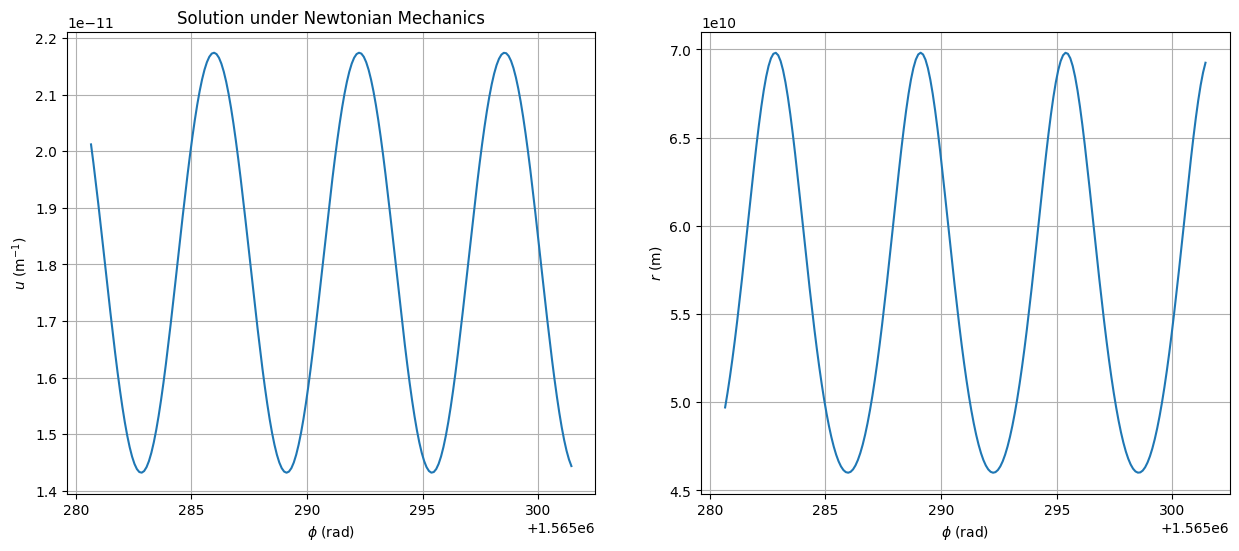

In [139]:
def newt(angle):
    return grav_const * sun_mass / h_sq * (1 + ecc * np.cos(angle))
unewt = newt(phi)
unewt_plot = newt(phi_plot)
unewt_plot1 = newt(phi_plot1)
unewt_plot2 = newt(phi_plot2)
unewt_plot3 = newt(phi_plot3)
unewt_plot4 = newt(phi_plot4)
plt.rcParams.update({'figure.figsize': [15, 6]} )
plt.subplot(1, 2, 1)
plt.plot(phi_plot4, unewt_plot4)
plt.grid()
plt.xlabel(r'$\phi$ (rad)')
plt.ylabel(r'$u\ (\mathrm{m}^{-1})$')
plt.title('Solution under Newtonian Mechanics')

rnewt = 1 / np.array(unewt)
rnewt_plot = 1 / np.array(unewt_plot)
rnewt_plot1 = 1 / np.array(unewt_plot1)
rnewt_plot2 = 1 / np.array(unewt_plot2)
rnewt_plot3 = 1 / np.array(unewt_plot3)
rnewt_plot4 = 1 / np.array(unewt_plot4)
plt.subplot(1, 2, 2)
plt.plot(phi_plot4, rnewt_plot4)
plt.grid()
plt.xlabel(r'$\phi$ (rad)')
plt.ylabel(r'$r\ (\mathrm{m})$')

By writing the solution for the GR case:
\begin{equation}
u = \frac{GM}{h^2} (1 + ecos\phi) + \Delta u.
\end{equation}
Substituting the solution back to the non-linear ODE, can write a 2nd-order linear ODE of perturbation term \Delta u:
\begin{equation}
\frac{d^2 \Delta u}{d\phi^2} + \Delta u = A (1 + e^2cos^2\phi + 2ecos\phi),
\end{equation}
where $A = \frac{3(GM)^3}{c^2h^4}$.
The ODE can be solved analytically and gives the solution:
\begin{equation}
\Delta u = A (1 + e^2(\frac{1}{2} - \frac{1}{6}cos2\phi) + e\phi cos\phi).
\end{equation}
By proper approximation, the full solution is:
\begin{equation}
u = \frac{GM}{h^2} (1 + ecos\phi) + A (1 + e^2(\frac{1}{2} - \frac{1}{6}cos2\phi) + e\phi cos\phi).
\end{equation}
Here, we can take the same initial conditions as above and plot.

Text(0, 0.5, '$r\\ (\\mathrm{m})$')

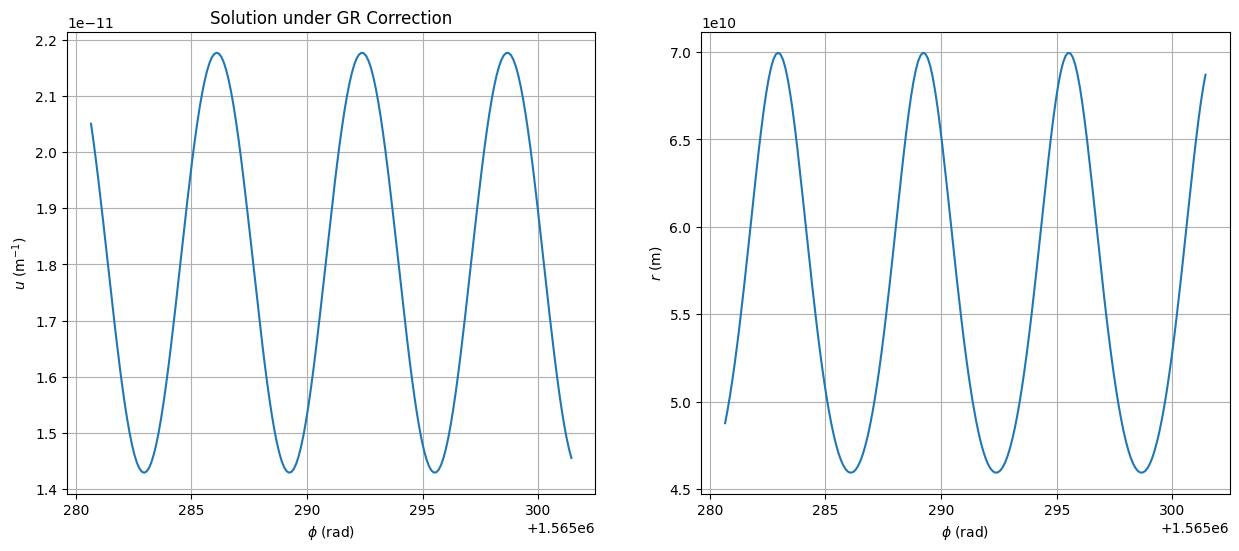

In [140]:
A = 3 * (grav_const * sun_mass)**3 / (speed_of_light * h_sq)**2
def gr(angle):
   delta = A * (1 + ecc**2 * (1/2 - 1/6 * np.cos(2*angle)) + ecc * angle * np.sin(angle))
   return newt(angle) + delta
ugr = gr(phi)
ugr_plot = gr(phi_plot)
ugr_plot1 = gr(phi_plot1)
ugr_plot2 = gr(phi_plot2)
ugr_plot3 = gr(phi_plot3)
ugr_plot4 = gr(phi_plot4)

#plot the result
plt.rcParams.update({'figure.figsize': [15, 6]} )

plt.subplot(1, 2, 1)
plt.plot(phi_plot4, ugr_plot4)
plt.grid()
plt.xlabel(r'$\phi$ (rad)')
plt.ylabel(r'$u\ (\mathrm{m}^{-1})$')
plt.title('Solution under GR Correction')


rgr = 1/np.array(ugr)
rgr_plot = 1/np.array(ugr_plot)
rgr_plot1 = 1 / np.array(ugr_plot1)
rgr_plot2 = 1 / np.array(ugr_plot2)
rgr_plot3 = 1/np.array(ugr_plot3)
rgr_plot4 = 1/np.array(ugr_plot4)
plt.subplot(1, 2, 2)
plt.plot(phi_plot4, rgr_plot4)
plt.grid()
plt.xlabel(r'$\phi$ (rad)')
plt.ylabel(r'$r\ (\mathrm{m})$')

For comparison:

We define the two orbits overlap at the beginning.

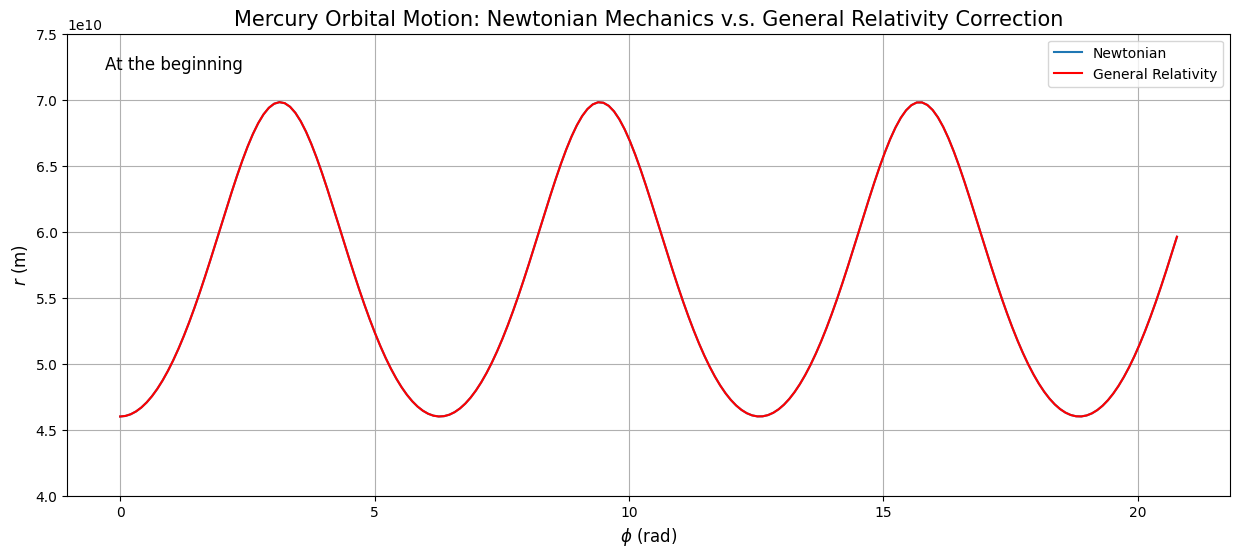

In [141]:
plt.figure()
plt.title('Mercury Orbital Motion: Newtonian Mechanics v.s. General Relativity Correction', size=15)
plt.plot(phi_plot1, rnewt_plot1, label='Newtonian')
plt.plot(phi_plot1, rgr_plot1, label='General Relativity', c='red')
plt.grid()
plt.legend()
plt.xlabel(r'$\phi$ (rad)', size=12)
plt.ylabel(r'$r\ (\mathrm{m})$', size=12)
plt.figtext(0.15, 0.82, r"At the beginning", fontsize=12)
plt.yticks(np.arange(4.0e10, 8.0e10, 0.5e10))
plt.savefig('ODE_solution_1.png')

End of the $200^{th}$ century.

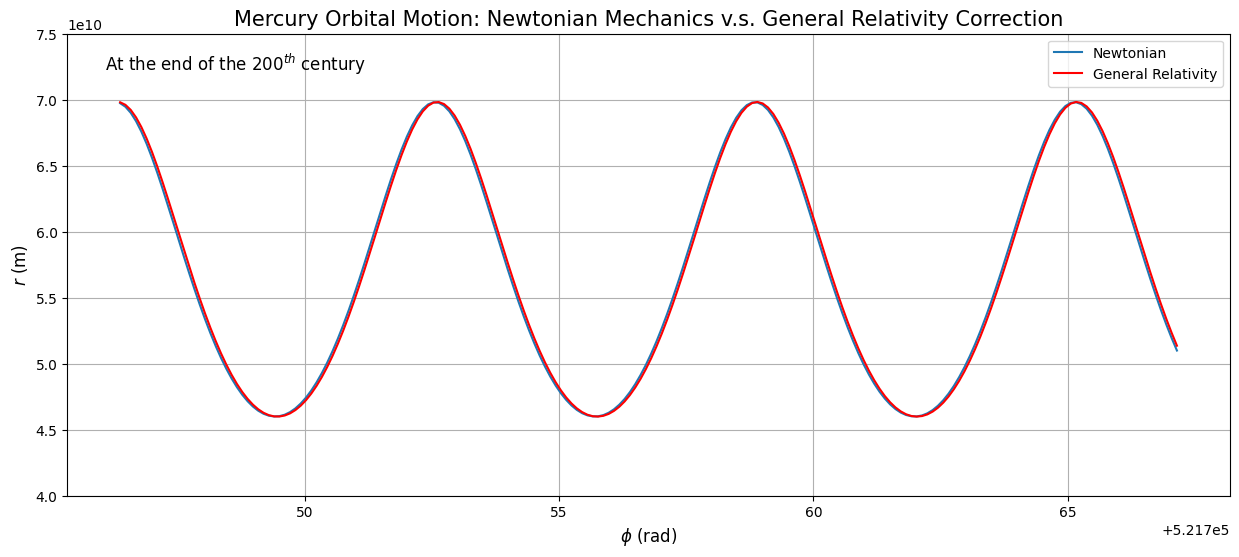

In [142]:
plt.figure()
plt.title('Mercury Orbital Motion: Newtonian Mechanics v.s. General Relativity Correction', size=15)
plt.plot(phi_plot2, rnewt_plot2, label='Newtonian')
plt.plot(phi_plot2, rgr_plot2, label='General Relativity', c='red')
plt.grid()
plt.legend()
plt.xlabel(r'$\phi$ (rad)', size=12)
plt.ylabel(r'$r\ (\mathrm{m})$', size=12)
plt.yticks(np.arange(4.0e10, 8.0e10, 0.5e10))
plt.figtext(0.15, 0.82, r"At the end of the $200^{th}$ century", fontsize=12)
plt.savefig('ODE_solution_2.png')

End of the $400^{th}$ century.

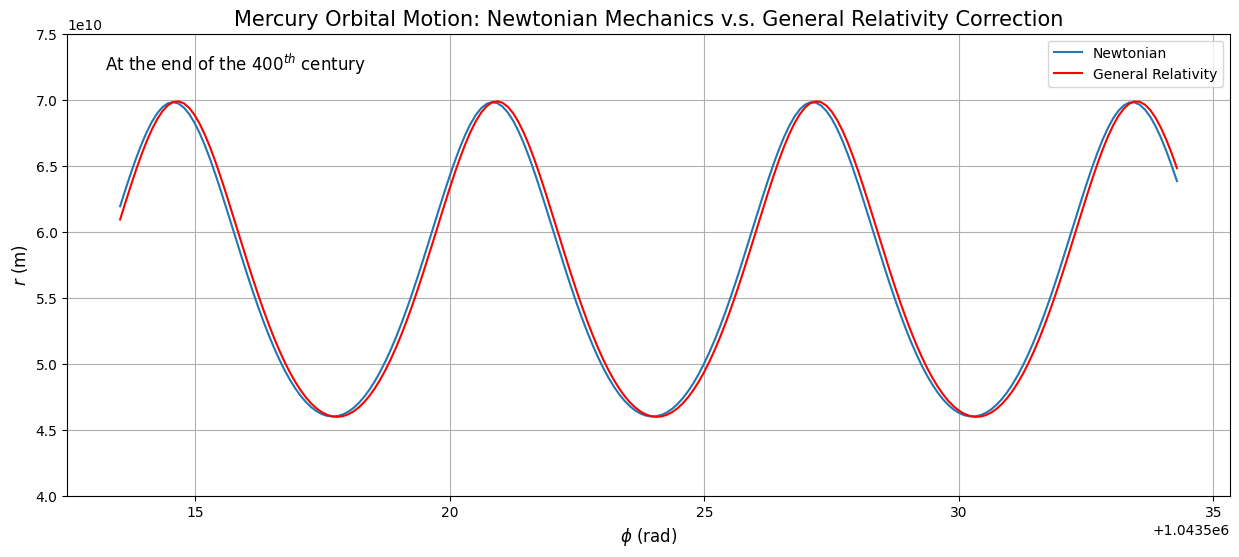

In [143]:
plt.figure()
plt.title('Mercury Orbital Motion: Newtonian Mechanics v.s. General Relativity Correction', size=15)
plt.plot(phi_plot3, rnewt_plot3, label='Newtonian')
plt.plot(phi_plot3, rgr_plot3, label='General Relativity', c='red')
plt.grid()
plt.legend()
plt.xlabel(r'$\phi$ (rad)', size=12)
plt.ylabel(r'$r\ (\mathrm{m})$', size=12)
plt.yticks(np.arange(4.0e10, 8.0e10, 0.5e10))
plt.figtext(0.15, 0.82, r"At the end of the $400^{th}$ century", fontsize=12)
plt.savefig('ODE_solution_3.png')

End of the $600^{th}$ century.

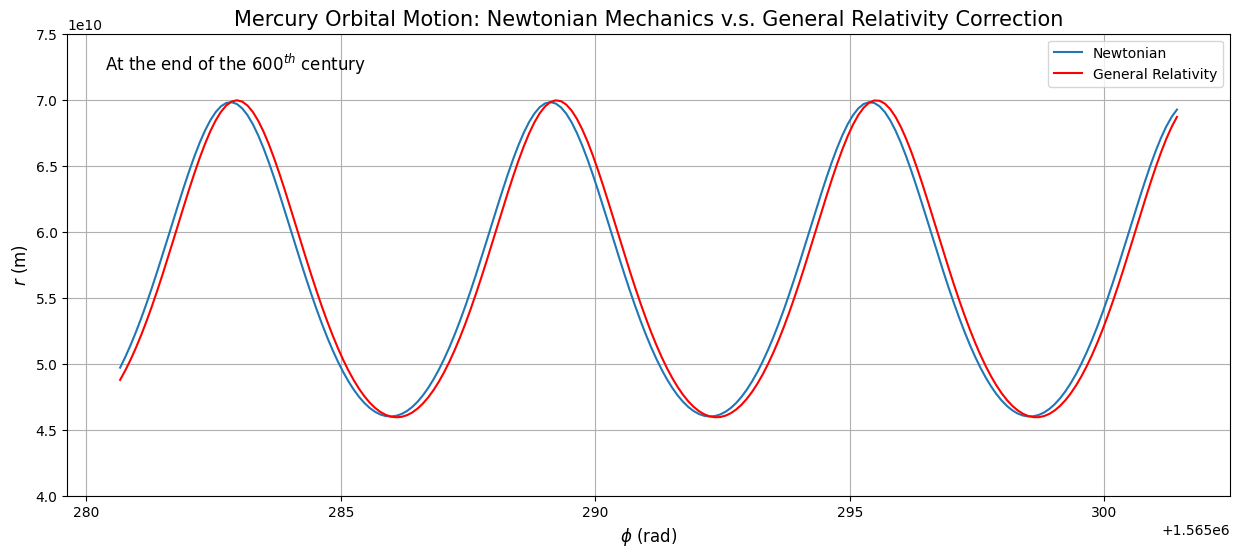

In [144]:
plt.figure()
plt.title('Mercury Orbital Motion: Newtonian Mechanics v.s. General Relativity Correction', size=15)
plt.plot(phi_plot4, rnewt_plot4, label='Newtonian')
plt.plot(phi_plot4, rgr_plot4, label='General Relativity', c='red')
plt.grid()
plt.legend()
plt.xlabel(r'$\phi$ (rad)', size=12)
plt.ylabel(r'$r\ (\mathrm{m})$', size=12)
plt.yticks(np.arange(4.0e10, 8.0e10, 0.5e10))
plt.figtext(0.15, 0.82, r"At the end of the $600^{th}$ century", fontsize=12)
plt.savefig('ODE_solution.png')

Find the angle shifted by finding the perihelion point (this method is not working because of limited number of data points).

124562


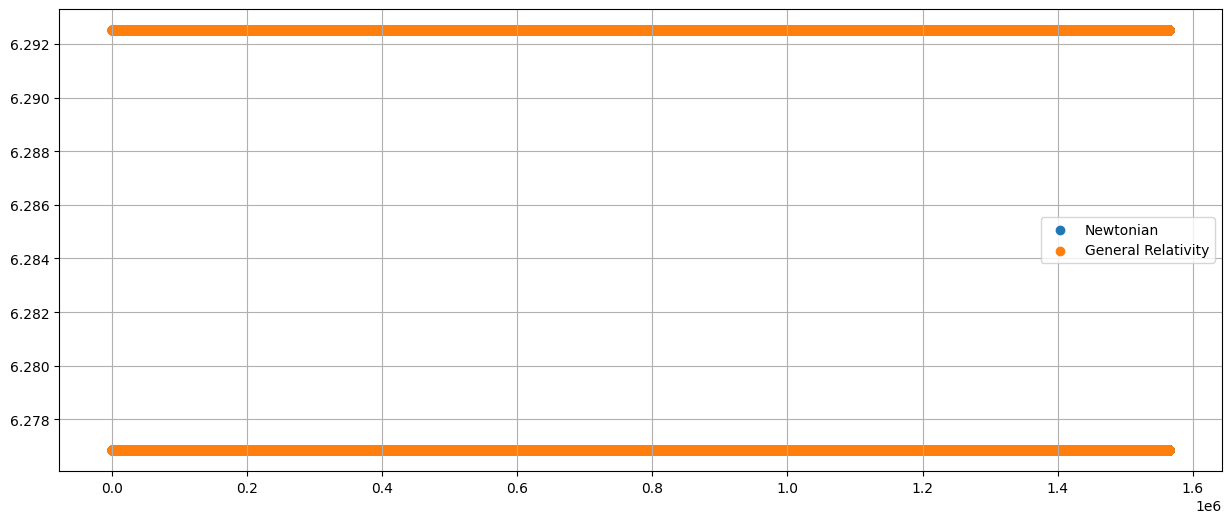

In [146]:
newt_min_indx = argrelextrema(rnewt, np.less, order=3)
newt_min_arr = newt_min_indx[0]
i = 0
newt_seps = []
while i <= len(newt_min_arr) - 2:
    newt_sep = phi[newt_min_arr[i+1]] - phi[newt_min_arr[i]]
    newt_seps.append(newt_sep)
    i += 1
gr_min_indx = argrelextrema(rgr, np.less, order=3)
gr_min_arr = gr_min_indx[0]
gr_seps = []
j = 0
while j <= len(gr_min_arr) - 2:
    gr_sep = phi[gr_min_arr[j+1]] - phi[gr_min_arr[j]]
    gr_seps.append(gr_sep)
    j += 1

n = 0
newt_sep_avg = []
while n <= len(newt_seps) - 2:
    newt_sep = (newt_seps[n] + newt_seps[n+1])/2
    newt_sep_avg.append(newt_sep)
    n += 2
m = 0
gr_sep_avg = []
while m <= len(gr_seps) - 2:
    gr_sep = (gr_seps[m] + gr_seps[m+1])/2
    gr_sep_avg.append(gr_sep)
    m += 2
print(len(gr_sep_avg))
#newt_seps = [n for n in newt_seps if n < 6.30]
#gr_seps = [g for g in gr_seps if g < 6.30]
time = np.arange(0, len(gr_seps)*earth_period, earth_period)
plt.scatter(phi[newt_min_arr[:-1]], newt_seps, label='Newtonian')
plt.scatter(phi[gr_min_arr[:-1]], gr_seps, label='General Relativity')
plt.legend()
plt.grid()

Check if the single data looks right (turns out to be right!).

In [147]:
print((phi[gr_min_arr[-1]] - phi[newt_min_arr[-1]]))

0.12522411555983126


Plot the $\phi$ values corresponding to the perihelion against time for two models and calculate the rate of precession by comparing their gradients.

Newtonian slope: 0.0714247854472344, GR slope: 0.07142479112736984
Regression rate: 5.680135431451738e-09
Perihelion of Mercury precesses 42.794'' per century.


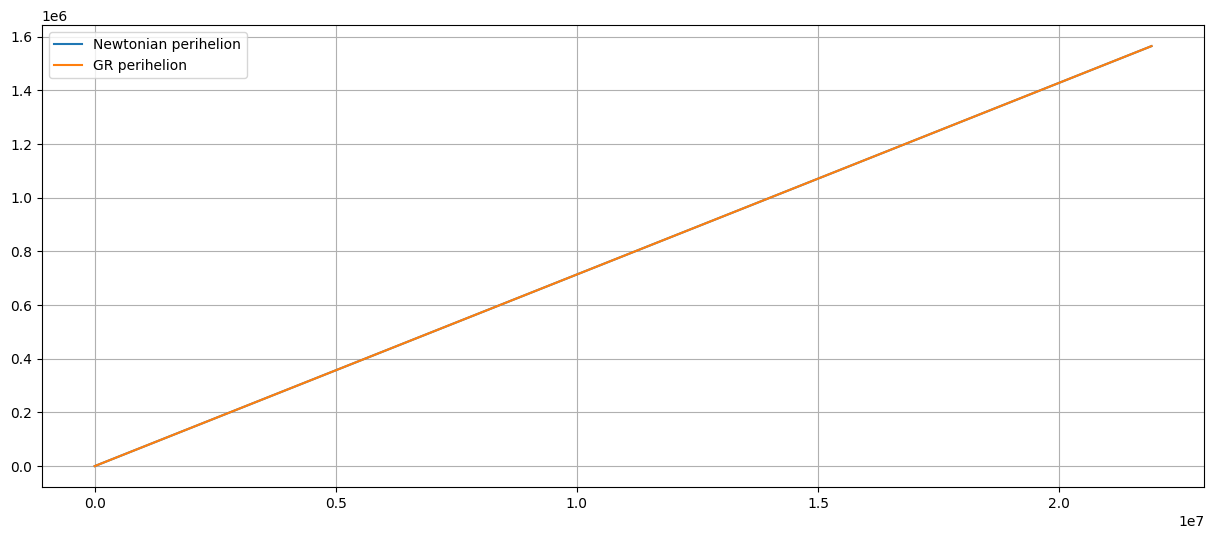

In [148]:
newt_min_indx = argrelextrema(np.array(rnewt), np.less)[0]
gr_min_indx = argrelextrema(np.array(rgr), np.less)[0]
newt_min_arr = np.array(newt_min_indx)
gr_min_arr = np.array(gr_min_indx)
newt_min_phi = phi[newt_min_arr]
gr_min_phi = phi[gr_min_arr]
phi_difference = gr_min_phi - newt_min_phi
newt_time = np.arange(0, mercury_period * len(newt_min_phi), mercury_period)
gr_time = np.arange(0, mercury_period * len(gr_min_phi), mercury_period)
slope_newt, intercept_newt = np.polyfit(newt_time, newt_min_phi, deg=1)
slope_gr, intercept_gr = np.polyfit(gr_time, gr_min_phi, deg=1)
print(f'Newtonian slope: {slope_newt}, GR slope: {slope_gr}')
rate_of_progression = np.abs(slope_newt - slope_gr)
print(f'Regression rate: {rate_of_progression}')
plt.plot(newt_time, newt_min_phi, label='Newtonian perihelion')
plt.plot(gr_time, gr_min_phi, label = 'GR perihelion')
plt.grid()
plt.legend()
precession_angle_per_century = rate_of_progression * earth_period * 100 / np.pi * 180 * 3600
print(f"Perihelion of Mercury precesses {precession_angle_per_century:.3f}'' per century.")
